In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [3]:
# Load dataset
df = pd.read_csv("sweet_potato_leaf2.csv")

# Display first 5 rows
display(df.head())

# Check dataset information
print(df.info())

# Check missing values
print(df.isnull().sum())

# Check target distribution
print("\nIrrigation target distribution:")
print(df["irrigation_need"].value_counts())

print("\nVentilation target distribution:")
print(df["ventilation_need"].value_counts())

,id,created_at,temperature,humidity,light,soil_moisture,ph_value,malaysia_time,ventilation_need,irrigation_need
0,1,2026-09-16 14:34:46.552740+00,28.7,52.1,2996,86,6.84,9/16/2026 22:34,0,0
1,2,2026-09-16 14:44:46.552740+00,27.9,53.1,2462,87,6.71,9/16/2026 22:44,0,0
2,3,2026-09-16 14:54:46.552740+00,27.5,52.3,2839,87,6.73,9/16/2026 22:54,0,0
3,4,2026-09-16 15:04:46.552740+00,27.1,52.5,2801,87,6.72,9/16/2026 23:04,0,0
4,5,2026-09-16 15:14:46.552740+00,26.9,51.9,2973,87,6.74,9/16/2026 23:14,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3033 entries, 0 to 3032
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                3033 non-null   int64  
 1   created_at        3033 non-null   object 
 2   temperature       3033 non-null   float64
 3   humidity          3033 non-null   float64
 4   light             3033 non-null   int64  
 5   soil_moisture     3033 non-null   int64  
 6   ph_value          3033 non-null   float64
 7   malaysia_time     3033 non-null   object 
 8   ventilation_need  3033 non-null   int64  
 9   irrigation_need   3033 non-null   int64  
dtypes: float64(3), int64(5), object(2)
memory usage: 237.1+ KB
None
id                  0
created_at          0
temperature         0
humidity            0
light               0
soil_moisture       0
ph_value            0
malaysia_time       0
ventilation_need    0
irrigation_need     0
dtype: int64

Irrigation target distribu

In [4]:
features = [
    "temperature",
    "humidity",
    "soil_moisture"
]

X = df[features]

# Two prediction targets
y_irrigation = df["irrigation_need"]
y_ventilation = df["ventilation_need"]

In [8]:
# Irrigation dataset split
X_train_irr, X_test_irr, y_train_irr, y_test_irr = train_test_split(
    X,
    y_irrigation,
    test_size=0.3,
    random_state=42
)

# Ventilation dataset split
X_train_vent, X_test_vent, y_train_vent, y_test_vent = train_test_split(
    X,
    y_ventilation,
    test_size=0.3,
    random_state=42
)

print("Irrigation training samples:", len(X_train_irr))
print("Irrigation testing samples:", len(X_test_irr))

print("Ventilation training samples:", len(X_train_vent))
print("Ventilation testing samples:", len(X_test_vent))

Irrigation training samples: 2123
Irrigation testing samples: 910
Ventilation training samples: 2123
Ventilation testing samples: 910


In [9]:
# Create Random Forest models
rf_irrigation = RandomForestClassifier(
    random_state=42
)

rf_ventilation = RandomForestClassifier(
    random_state=42
)

# Train irrigation model
rf_irrigation.fit(X_train_irr, y_train_irr)

# Train ventilation model
rf_ventilation.fit(X_train_vent, y_train_vent)

print("Both Random Forest models have been trained successfully!")

Both Random Forest models have been trained successfully!



Irrigation Random Forest
Accuracy : 0.9967
Precision: 0.9412
Recall   : 0.8889
F1-score : 0.9143

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       892
           1       0.94      0.89      0.91        18

    accuracy                           1.00       910
   macro avg       0.97      0.94      0.96       910
weighted avg       1.00      1.00      1.00       910



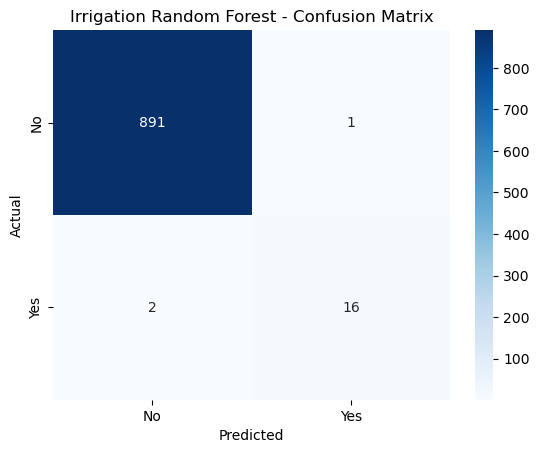


Ventilation Random Forest
Accuracy : 0.9835
Precision: 0.9931
Recall   : 0.9863
F1-score : 0.9897

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       182
           1       0.99      0.99      0.99       728

    accuracy                           0.98       910
   macro avg       0.97      0.98      0.97       910
weighted avg       0.98      0.98      0.98       910



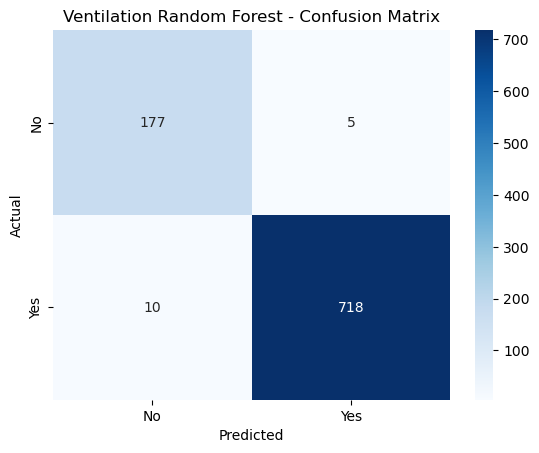

In [10]:
# Predictions
y_pred_irr = rf_irrigation.predict(X_test_irr)
y_pred_vent = rf_ventilation.predict(X_test_vent)


def evaluate_model(y_true, y_pred, model_name):

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_true, y_pred, zero_division=0), 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


# Evaluate irrigation model
evaluate_model(
    y_test_irr,
    y_pred_irr,
    "Irrigation Random Forest"
)

# Evaluate ventilation model
evaluate_model(
    y_test_vent,
    y_pred_vent,
    "Ventilation Random Forest"
)

In [102]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

In [103]:
grid_irr = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_irr.fit(X_train_irr, y_train_irr)

best_rf_irrigation = grid_irr.best_estimator_

print("Best Irrigation Parameters:")
print(grid_irr.best_params_)

print("Best Irrigation CV F1-score:")
print(round(grid_irr.best_score_, 4))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Irrigation Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best Irrigation CV F1-score:
0.8538


In [104]:
grid_vent = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_vent.fit(X_train_vent, y_train_vent)

best_rf_ventilation = grid_vent.best_estimator_

print("Best Ventilation Parameters:")
print(grid_vent.best_params_)

print("Best Ventilation CV F1-score:")
print(round(grid_vent.best_score_, 4))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Ventilation Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
Best Ventilation CV F1-score:
0.992



Tuned Irrigation Random Forest
Accuracy : 0.9978
Precision: 0.9444
Recall   : 0.9444
F1-score : 0.9444

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       892
           1       0.94      0.94      0.94        18

    accuracy                           1.00       910
   macro avg       0.97      0.97      0.97       910
weighted avg       1.00      1.00      1.00       910



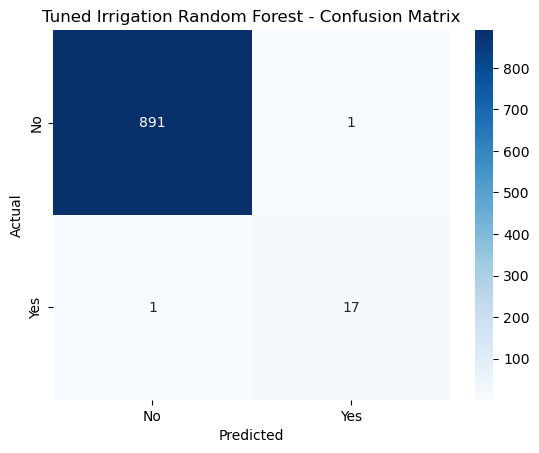


Tuned Ventilation Random Forest
Accuracy : 0.9813
Precision: 0.9944
Recall   : 0.9821
F1-score : 0.9883

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95       182
           1       0.99      0.98      0.99       728

    accuracy                           0.98       910
   macro avg       0.96      0.98      0.97       910
weighted avg       0.98      0.98      0.98       910



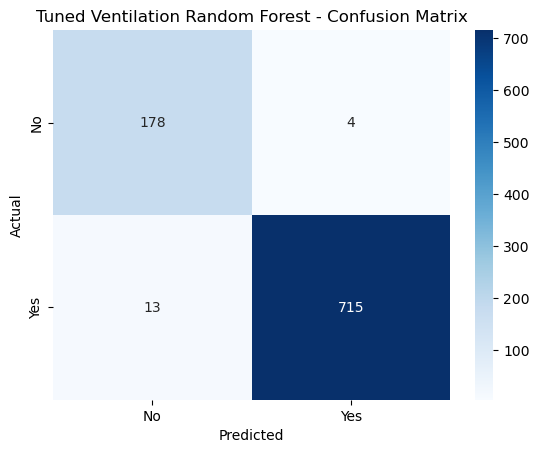

In [105]:
# Tuned model predictions
y_pred_irr_tuned = best_rf_irrigation.predict(X_test_irr)
y_pred_vent_tuned = best_rf_ventilation.predict(X_test_vent)

# Evaluate tuned models
evaluate_model(
    y_test_irr,
    y_pred_irr_tuned,
    "Tuned Irrigation Random Forest"
)

evaluate_model(
    y_test_vent,
    y_pred_vent_tuned,
    "Tuned Ventilation Random Forest"
)

         Feature  Importance
2  soil_moisture    0.699864
1       humidity    0.199659
0    temperature    0.100476


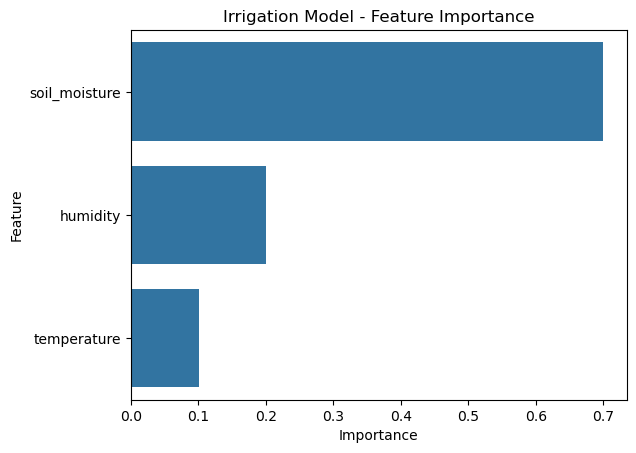

         Feature  Importance
1       humidity    0.743811
0    temperature    0.191528
2  soil_moisture    0.064662


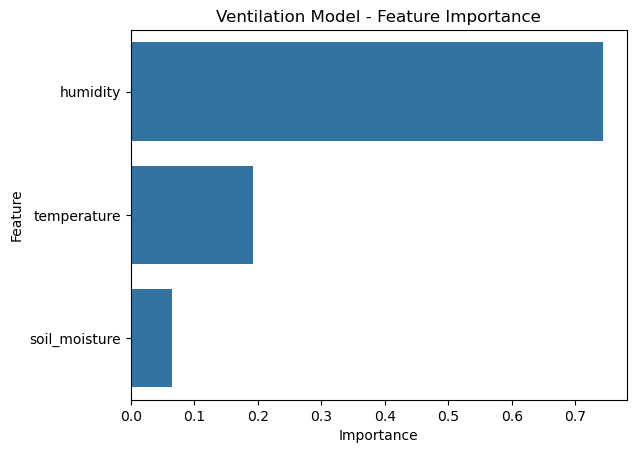

In [106]:
def plot_feature_importance(model, model_name):

    importance = pd.DataFrame({
        "Feature": features,
        "Importance": model.feature_importances_
    })

    importance = importance.sort_values(
        by="Importance",
        ascending=False
    )

    print(importance)

    sns.barplot(
        data=importance,
        x="Importance",
        y="Feature"
    )

    plt.title(f"{model_name} - Feature Importance")
    plt.show()


plot_feature_importance(
    best_rf_irrigation,
    "Irrigation Model"
)

plot_feature_importance(
    best_rf_ventilation,
    "Ventilation Model"
)